# 03 — Single-object tracking: please keep one box on the same creature

[Background subtraction](./01_motion_and_background_subtraction.ipynb) found candidate regions. [Optical flow](./02_optical_flow_and_point_tracking.ipynb) followed anonymous points. Now we finally maintain one declared target: **this box contains the object I care about; please find it again in every frame**.

The request sounds modest until the target grows, disappears behind a tree, and acquires a suspiciously similar colleague.

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from _helpers.motion_background import ensure_opencv_sample_video, read_video_frames
from _helpers.single_object import (
    make_single_object_sequence,
    plot_real_mil_tracking,
    plot_scale_comparison,
    plot_search_strategies,
    plot_template_match_pair,
    plot_tracker_metrics,
    plot_tracking_contract,
    run_template_tracker,
    track_real_video_mil,
)
from wave_part_dual.tracking import box_iou, match_template

plt.rcParams['figure.dpi'] = 75

## 1. The tracking contract

A single-object tracker normally begins with an **initial bounding box** supplied by a detector or human. After that, each update should return a new box for the same target. Unlike detection, it is not asked to discover every object or decide what class the target belongs to.

Our synthetic answer key stores the true box in every frame. The tracker never receives future true boxes; we use them afterward to measure how badly reality disagrees with confidence.

The robot slowly grows as if approaching the camera, passes behind the tree, and eventually meets a look-alike carrying a question mark. The simulation has begun producing narrative complications without approval.

> If synthetic robot casting, tree placement, and unauthorized twin production suddenly become your calling: [`make_single_object_sequence()` implementation](./_helpers/single_object.py). Everyone else may safely enjoy the scene without entering the factory.

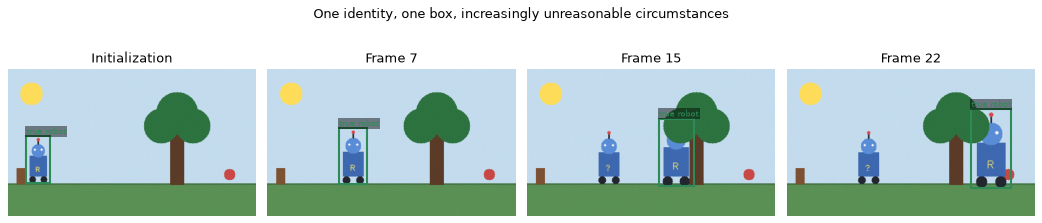

In [2]:
frames, true_boxes, true_scales = make_single_object_sequence()
plot_tracking_contract(frames, true_boxes)

### How do we judge a box?

**Intersection over Union (IoU)** compares the overlapping area of the predicted and true boxes with their combined area:

- `1.0` means perfect overlap;
- around `0.5` means partial but recognizable agreement;
- `0.0` means the tracker is confidently supervising somebody else.

We already met IoU in object detection. Here it lets synthetic truth evaluate a tracker frame by frame.

In [3]:
x, y, width, height = true_boxes[10]
initial_width, initial_height = true_boxes[0][2:]
fixed_size_box = (
    round(x + (width - initial_width) / 2),
    round(y + (height - initial_height) / 2),
    initial_width,
    initial_height,
)
print('Perfect box:', box_iou(true_boxes[10], true_boxes[10]))
print('Correct center but old size:', round(box_iou(fixed_size_box, true_boxes[10]), 3))

Perfect box: 1.0
Correct center but old size: 0.576


## 2. Template matching: carry one photograph and slide it everywhere

The simplest appearance model is the target patch from the initial box. OpenCV's `matchTemplate` slides that patch over a search image and calculates a similarity score at every possible position. The best score becomes the new box.

This is closer to repeated matching than a sophisticated modern tracker, which is exactly why its decisions remain visible. The correlation heatmap shows all candidate positions: brighter means *this patch resembles the remembered robot more*.

> Optional official reassurance: [OpenCV's template-matching tutorial](https://docs.opencv.org/4.x/de/da9/tutorial_template_matching.html). Curious about our reusable machinery? [`match_template()` implementation](../../src/wave_part_dual/tracking/single_object.py).

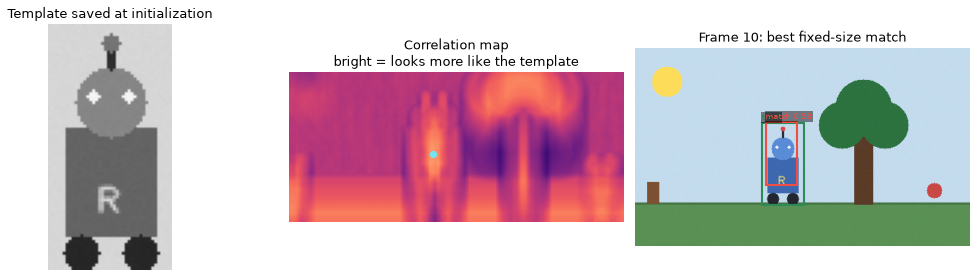

In [4]:
single_match = plot_template_match_pair(
    frames, true_boxes, template_index=0, target_index=10
)

The initial template still locates the robot, but its box remains the original size while the true robot has grown. Finding approximately the right place and estimating the right extent are related but separate problems.

## 3. Global search versus local search

A tracker can search the entire image every time or trust the previous position and inspect only its neighborhood.

- **Global search** can recover after a large jump or disappearance, but any convincing look-alike may steal the box.
- **Local search** is faster and uses motion continuity as a quiet assumption, but once it loses the target, the real target may remain outside its search region forever.

Both trackers below use the same fixed initial template. Only the search area changes.

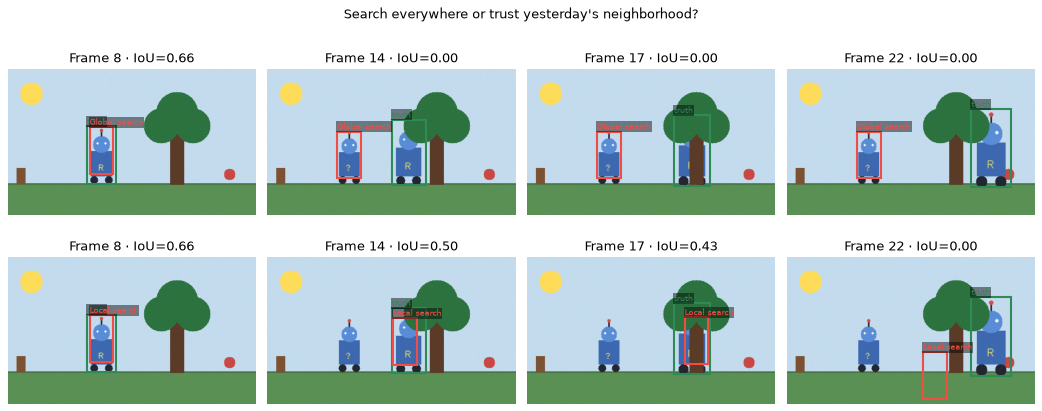

In [5]:
global_boxes, global_scores, _ = run_template_tracker(
    frames, true_boxes[0], search='global', scales=(1.0,)
)
local_boxes, local_scores, _ = run_template_tracker(
    frames, true_boxes[0], search='local', search_margin=45, scales=(1.0,)
)
plot_search_strategies(
    frames, true_boxes, global_boxes, local_boxes, frame_indices=(8, 14, 17, 22)
)

> **Observation:** when the look-alike appears, global search immediately finds its cleaner resemblance to the old template. Local search ignores that distant temptation and follows the real robot longer, but tree occlusion eventually damages its location. Global recovery and local loyalty both have invoices attached.

> **Are the previous notebooks hiding underneath this tracker?** Not here. Our template tracker does not use background subtraction or optical flow: it repeatedly searches for the saved appearance, and local search merely limits that search around the previous box. A larger system could combine all three—background subtraction proposes moving regions, optical flow predicts movement, and appearance matching checks which candidate still resembles the target—but today each tool is being allowed to commit its own mistakes in public.

## 4. Scale change: the target outgrows its old photograph

Our fixed template always produces the original box size. A small improvement is to resize the template to several candidate scales and keep the best score. This costs more comparisons but lets the estimated box grow.

The scale candidates are deliberately visible below. Change their range or spacing and watch the tracker negotiate with reality.

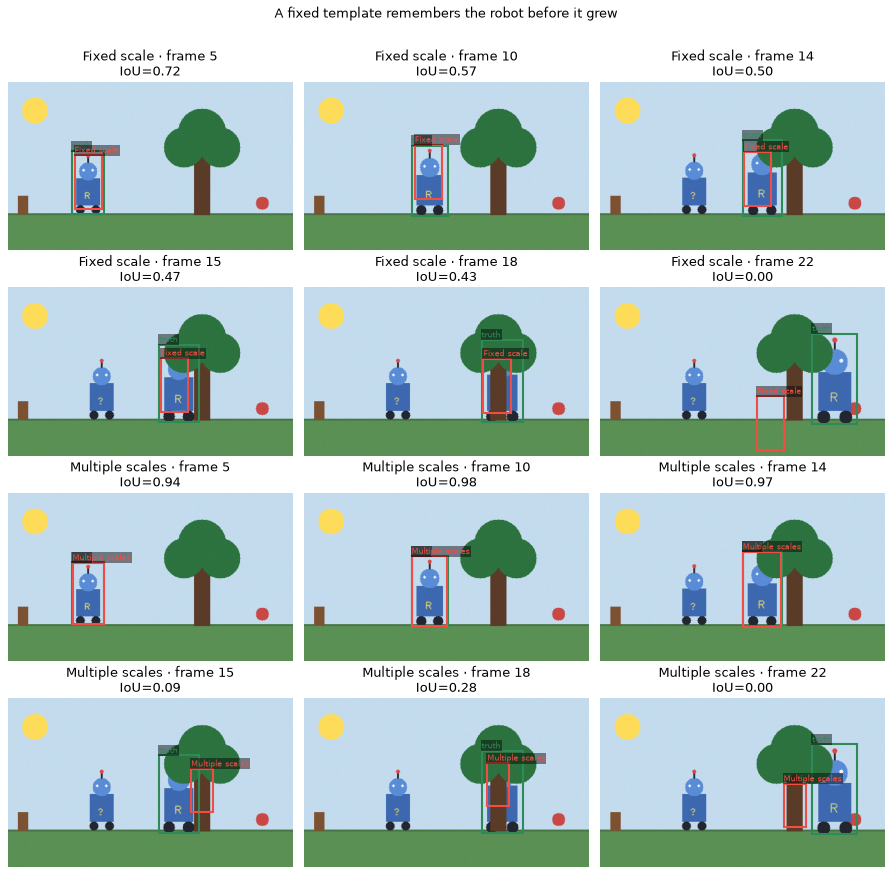

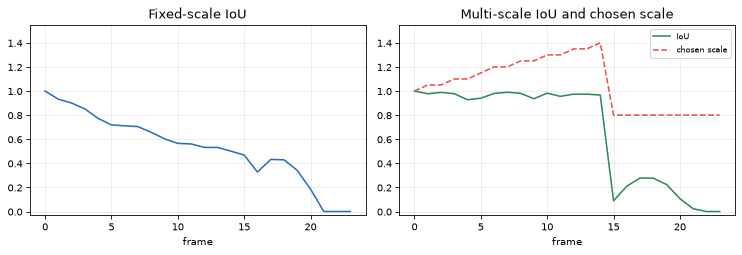

In [28]:
scale_candidates = tuple(np.round(np.linspace(0.80, 1.50, 15), 2))
multiscale_boxes, multiscale_scores, chosen_scales = run_template_tracker(
    frames,
    true_boxes[0],
    search='local',
    search_margin=55,
    scales=scale_candidates,
)
plot_scale_comparison(
    frames,
    true_boxes,
    local_boxes,
    multiscale_boxes,
    chosen_scales,
    frame_indices=(5, 10, 14, 15, 18, 22),
)

> **Observation:** before occlusion, multi-scale matching follows the robot's growth and keeps much better IoU. Near the tree, the preferred scale can suddenly shrink because a small visible fragment matches better than the full hidden robot. Scale estimation cannot repair missing evidence; it merely offers more sizes in which to be confused.

## 5. Confidence is not correctness

Template similarity answers *how much does this patch resemble my memory?* IoU answers *is the predicted box actually on the true robot?* These are not the same question.

The tracker does not know IoU during real operation because the true box is unavailable. A high similarity score can belong to the wrong twin, while a partially occluded correct robot may receive a low score. Confidence is evidence produced by the model—not a certificate issued by reality.

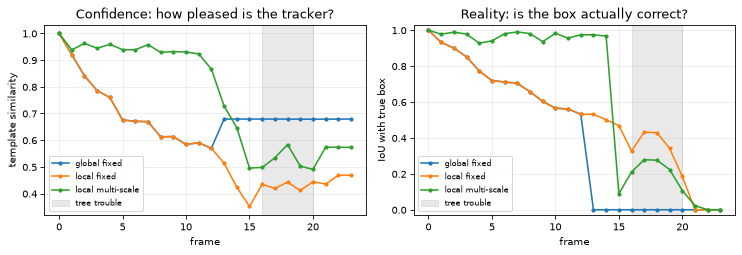

In [29]:
plot_tracker_metrics(
    true_boxes,
    {
        'global fixed': (global_boxes, global_scores),
        'local fixed': (local_boxes, local_scores),
        'local multi-scale': (multiscale_boxes, multiscale_scores),
    },
    occlusion=(16, 20),
)

A practical tracker needs a failure policy: reject low confidence, wait, expand the search, ask a detector to find the object again, or admit that the target was lost. Continuing to draw a box is not the same as continuing to track correctly.

## 6. A real tracker with more machinery hidden inside

For a real example we initialize OpenCV's built-in **MIL tracker** around one pedestrian in `vtest.avi`. MIL means *Multiple Instance Learning*. We will allow the abbreviation to live without unpacking its entire statistical childhood today.

Unlike our fixed template, MIL updates an appearance model while tracking. It can tolerate more variation, but the same contract remains: one initial box goes in; one estimated box comes out per frame. It still cannot guarantee identity after every overlap or disappearance.

In [30]:
video_path = ensure_opencv_sample_video(
    Path('../../data/object_tracking/vtest.avi')
)
real_frames, fps = read_video_frames(video_path, maximum_frames=90)
print(f'Read {len(real_frames)} frames at {fps:.1f} FPS')

Read 90 frames at 10.0 FPS


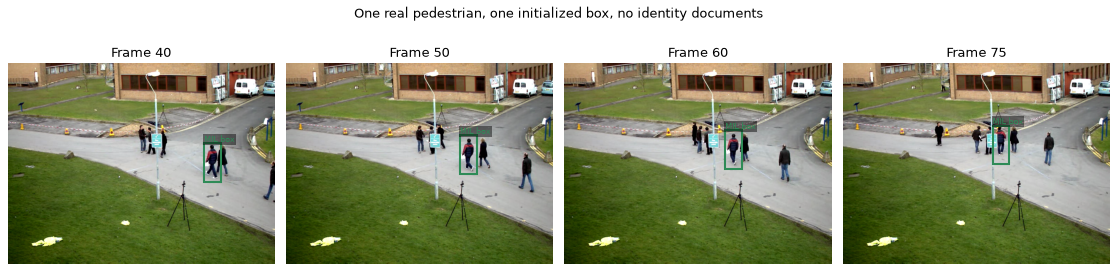

In [31]:
initial_pedestrian_box = (565, 230, 48, 110)  # x, y, width, height
mil_boxes, mil_success = track_real_video_mil(
    real_frames,
    initial_pedestrian_box,
    start_index=40,
    end_index=75,
)
plot_real_mil_tracking(real_frames, mil_boxes, mil_success)

The box follows one pedestrian across real frames without receiving new detections. This looks more like the behavior expected from a tracker, but the visualization alone cannot prove identity or accuracy—we lack true boxes for this video. A convincing rectangle remains capable of concealing surprisingly creative mistakes.

> If inspecting real tracking plumbing becomes your calling: [`track_real_video_mil()` implementation](./_helpers/single_object.py).

## Reflection

Short answers are sufficient; the tracker has already produced enough boxes.

1. What information does a single-object tracker receive that ordinary detection does not?
2. Why can global search recover more easily but also choose a look-alike?
3. Why does a fixed-size template lose IoU while still finding approximately the right position?
4. Why can similarity confidence remain high while IoU becomes zero?
5. What should a practical tracker do after deciding that the target is probably lost?

## Takeaway

Single-object tracking begins with an initialized target and tries to preserve its location and identity through time. Appearance matching supplies evidence; local search uses motion continuity; multiple scales handle growth; and confidence helps decide when evidence becomes weak.

None of these guarantees recovery after occlusion or protection from a convincing twin. The tracker must know not only how to update a box, but when to distrust it—and eventually when to ask for outside help.